# AVAX LONG — Breakout + RSI, xác nhận bằng volume, train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục (logic chung ở `reference/long_logic_engine.py`). Sửa **ô Cấu hình**, rồi chọn **Run All**. Kết quả lưu thành CSV cạnh notebook.

**Vào lệnh tại nến `i`:** breakout như bản RSI gốc **và** `volume[i] > vol_mult × SMA(volume, vol_window)[i-1]` (trung bình không gồm nến breakout).

**Stop (risk):** `sl_multiplier × (entry − lower)` như bản gốc. TP = `tp_sl_ratio` × risk, timeout `MAX_HOLDING_BARS` nến, phí vào lệnh `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R), một vị thế mỗi lúc — giống bản RSI gốc.

**Phí giữ lệnh:** tính mỗi 8 giờ trên mọi khung (`FEE_BARS = None` ⇒ 32 ở 15min, 8 ở 1h). Bản long RSI gốc dùng 8 ở 15min (gấp 4 lần phía short); ở đây đã chuẩn hoá.

`vol_mult = 0` là **tắt bộ lọc** = đúng bản breakout + RSI gốc (với phí 32). Grid search trên toàn khoảng train là **in-sample**; đánh giá ngoài mẫu bằng `reference/walk_forward_15min.py`. Ô **Kiểm tra CPU** so GPU với replay float64; ô replay cuối dùng chính replay đó để liệt kê từng lệnh.

In [27]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2023-01-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2025-01-01"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = None                     # None = CSV 5min mặc định của script
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

SCORE_FORMULA = "r_martin_monthly"
# Sửa trực tiếp các danh sách dưới đây để đổi grid. Số bộ tham số là tích số giá trị mỗi danh sách.
SEARCH_SPACES = {
    "boll_window": [6, 7, 8, 10, 12, 14, 16, 18, 20, 25, 30],
    "boll_window_dev": [1.8, 2.0, 2.2],
    "rsi_window": [30, 45, 60, 80],
    "rsi_threshold": [50, 55, 60, 65, 70],
    "vol_window": [20, 50, 100],
    "vol_mult": [0, 1.0, 1.5, 2.0, 3.0],
    "sl_multiplier": [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3],
    "tp_sl_ratio": [1.1],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288             # số nến tối đa giữ lệnh theo TIMEFRAME
FEE_BARS = None                    # None = 8 giờ mỗi lần phí (32 ở 15min)
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 50                     # bảng xếp hạng chỉ giữ bộ có nhiều lệnh hơn số này
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [28]:
# Nạp script cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "long_bollinger+RSI+volume"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER:
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

spec = importlib.util.spec_from_file_location("avax_long_bollinger_RSI_volume", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
print("CSV:", csv_path)
print("Đã nạp:", script_path)
print("Phí giữ lệnh: mỗi", strategy.resolve_fee_bars(TIMEFRAME, FEE_BARS), "nến")

CSV: C:\Users\Legion\Desktop\TradingProject\reference\long_bollinger+RSI\avaxusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\long_bollinger+RSI+volume\train_full_grid_gpu.py
Phí giữ lệnh: mỗi 32.0 nến


In [29]:
# Đọc dữ liệu 5 phút, resample và tạo grid
strategy.timeframe_nanos(TIMEFRAME)
start_date, end_date = START_DATE, END_DATE
expected_keys = set(strategy.SEARCH_SPACE)
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 70,272 nến; 2023-01-01 00:00:00 → 2025-01-01 23:45:00
Grid: 69,300 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,vol_window,vol_mult,sl_multiplier,tp_sl_ratio
0,6,1.8,30,50,20,0.0,0.7,1.1
1,6,1.8,30,50,20,0.0,0.8,1.1
2,6,1.8,30,50,20,0.0,0.9,1.1
3,6,1.8,30,50,20,0.0,1.0,1.1
4,6,1.8,30,50,20,0.0,1.1,1.1


In [30]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")

Thời gian: {'indicators_and_transfer_s': 0.3409990998916328, 'holding_fee_bars': 32.0, 'total_gpu_s': 1.7670458999928087}
Đã tính 69,300 bộ tham số


In [31]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = strategy.score_result(result, SCORE_FORMULA)
print("Score:", SCORE_FORMULA)

Score: r_martin_monthly


In [32]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với replay float64
if VERIFY_SAMPLES:
    strategy.verify_samples(bars, result, VERIFY_SAMPLES, MAX_HOLDING_BARS, FEE_BARS, TIMEFRAME)

In [33]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_{TIMEFRAME}_fp32.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[(result["number_of_trade"] > MIN_TRADES) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ và > {MIN_TRADES} lệnh: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\long_bollinger+RSI+volume\full_gpu_grid_results_15min_fp32.csv
Bộ có score hợp lệ và > 50 lệnh: 49,682/69,300


,boll_window,boll_window_dev,rsi_window,rsi_threshold,vol_window,vol_mult,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,number_of_trade,score,score_formula
66023,30,2.0,45,65,100,1.0,1.3,1.1,23.495710,2.40,0.38,0.963661,0.976976,0.665196,1.468704,0.670358,70,1.468704,r_martin_monthly
65946,30,2.0,45,65,20,0.0,1.3,1.1,23.484377,2.40,0.38,0.963696,0.976504,0.665196,1.467996,0.670188,70,1.467996,r_martin_monthly
65981,30,2.0,45,65,50,0.0,1.3,1.1,23.484377,2.40,0.38,0.963696,0.976504,0.665196,1.467996,0.670188,70,1.467996,r_martin_monthly
66016,30,2.0,45,65,100,0.0,1.3,1.1,23.484377,2.40,0.38,0.963696,0.976504,0.665196,1.467996,0.670188,70,1.467996,r_martin_monthly
65988,30,2.0,45,65,50,1.0,1.3,1.1,22.095604,2.40,0.39,0.968562,0.918758,0.666169,1.379165,0.636613,70,1.379165,r_martin_monthly
38731,16,1.8,45,65,100,2.0,0.7,1.1,31.525764,4.22,0.89,0.945265,1.310874,1.185541,1.105717,0.682263,97,1.105717,r_martin_monthly
18091,8,2.2,60,60,20,3.0,1.0,1.1,22.184322,3.09,0.51,0.878712,0.922447,0.878319,1.050241,0.621324,57,1.050241,r_martin_monthly
65953,30,2.0,45,65,20,1.0,1.3,1.1,19.952433,3.07,0.53,0.949619,0.829643,0.812605,1.020967,0.574533,68,1.020967,r_martin_monthly
55486,20,2.2,45,65,50,1.0,1.1,1.1,24.831783,3.10,0.54,0.955668,1.032531,1.025108,1.007241,0.619258,77,1.007241,r_martin_monthly
49228,18,2.2,45,65,100,1.5,1.1,1.1,25.305309,3.10,0.53,0.933082,1.052221,1.045868,1.006074,0.635602,79,1.006074,r_martin_monthly


,median_trades,median_performance,share_profitable,median_r_per_month,median_r_martin_monthly
vol_mult,,,,,
0.0,190.0,0.357,0.552,0.015,0.005
1.0,181.0,0.761,0.565,0.032,0.009
1.5,166.0,1.187,0.583,0.049,0.014
2.0,146.0,2.455,0.630,0.102,0.028
3.0,107.0,3.135,0.674,0.130,0.033


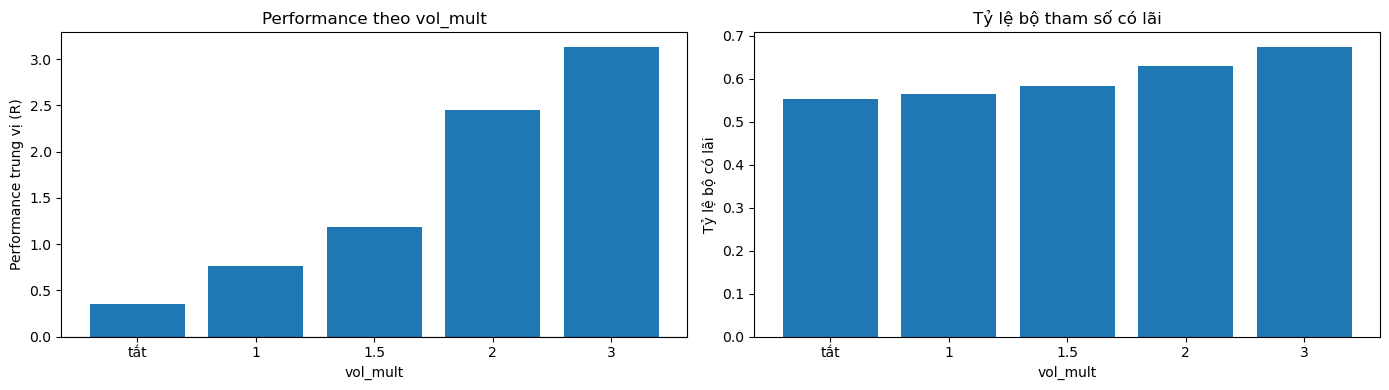

In [34]:
# Bộ lọc có giúp không? Trung vị toàn grid theo từng giá trị của `vol_mult` (ít nhiễu hơn bộ "tốt nhất").
by_filter = result.groupby("vol_mult").agg(
    median_trades=("number_of_trade", "median"),
    median_performance=("performance", "median"),
    share_profitable=("performance", lambda s: (s > 0).mean()),
    median_r_per_month=("r_per_month", "median"),
    median_r_martin_monthly=("r_martin_monthly", "median"),
)
display(by_filter.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
labels = [("tắt" if value == 0 else f"{value:g}") for value in by_filter.index]
axes[0].bar(labels, by_filter["median_performance"])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="vol_mult", ylabel="Performance trung vị (R)", title="Performance theo vol_mult")
axes[1].bar(labels, by_filter["share_profitable"])
axes[1].set(xlabel="vol_mult", ylabel="Tỷ lệ bộ có lãi", title="Tỷ lệ bộ tham số có lãi")
plt.tight_layout()
plt.show()

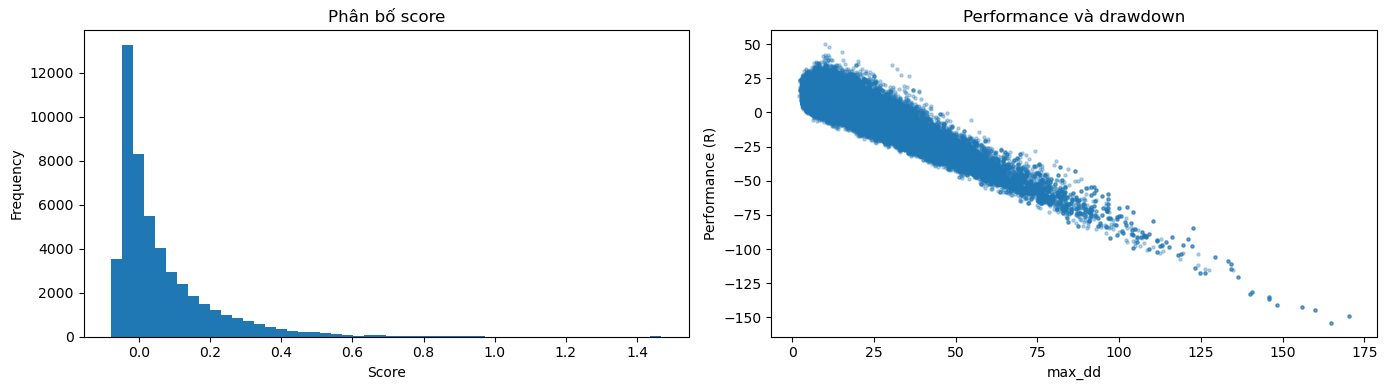

In [35]:
# Biểu đồ để xem phân bố score và hiệu quả/rủi ro của grid
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    axes[1].scatter(ranked["max_dd"], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel="max_dd", ylabel="Performance (R)", title="Performance và drawdown")
    plt.tight_layout()
    plt.show()

Giai đoạn backtest: 2023-01-01 00:00:00 đến 2025-06-20 12:45:00


,boll_window,boll_window_dev,rsi_window,rsi_threshold,vol_window,vol_mult,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,number_of_trade,score,score_formula
backtest_trial,30,2.0,45,65,100,1.0,1.3,1.1,24.633316,3.02,0.58,0.962656,0.831653,0.942225,0.882648,0.558624,86,0.882648,r_martin_monthly


Trial 66023: 86 lệnh; performance replay = 24.633302 R; GPU = 24.633316 R


,số lệnh
outcome,
target,37
timeout,36
stop,13


,entry_index,exit_index,open_timestamp,close_timestamp,entry_price,risk,stop_loss,take_profit,outcome,gross_r,entry_fee,holding_fee,net_r
0,124,300,2023-01-02 07:00:00,2023-01-04 03:00:00,11.112,0.560165,10.551835,11.728181,target,1.100000,0.019837,0.010910,1.069253
1,771,1034,2023-01-09 00:45:00,2023-01-11 18:30:00,12.368,0.864458,11.503542,13.318903,target,1.100000,0.014307,0.011759,1.073934
2,1272,1560,2023-01-14 06:00:00,2023-01-17 06:00:00,17.926,2.957033,14.968967,21.178736,timeout,-0.356777,0.006062,0.005456,-0.368295
3,1904,2192,2023-01-20 20:00:00,2023-01-23 20:00:00,16.967,1.401749,15.565251,18.508924,timeout,0.560015,0.012104,0.010894,0.537017
4,2575,2590,2023-01-27 19:45:00,2023-01-27 23:30:00,19.243,2.201326,17.041674,21.664459,target,1.100000,0.008742,0.000410,1.090849
5,3064,3352,2023-02-01 22:00:00,2023-02-04 22:00:00,20.881,3.598113,17.282887,24.838925,timeout,0.108112,0.005803,0.005223,0.097086
6,4396,4404,2023-02-15 19:00:00,2023-02-15 21:00:00,18.874,0.721461,18.152539,19.667607,target,1.100000,0.026161,0.000654,1.073185
7,6807,6966,2023-03-12 21:45:00,2023-03-14 13:30:00,15.433,1.844307,13.588693,17.461738,target,1.100000,0.008368,0.004158,1.087474
8,6969,7257,2023-03-14 14:15:00,2023-03-17 14:15:00,17.589,2.482059,15.106941,20.319265,timeout,-0.450835,0.007086,0.006378,-0.464300
9,7295,7583,2023-03-17 23:45:00,2023-03-20 23:45:00,17.648,2.024130,15.623870,19.874543,timeout,-0.502438,0.008719,0.007847,-0.519004


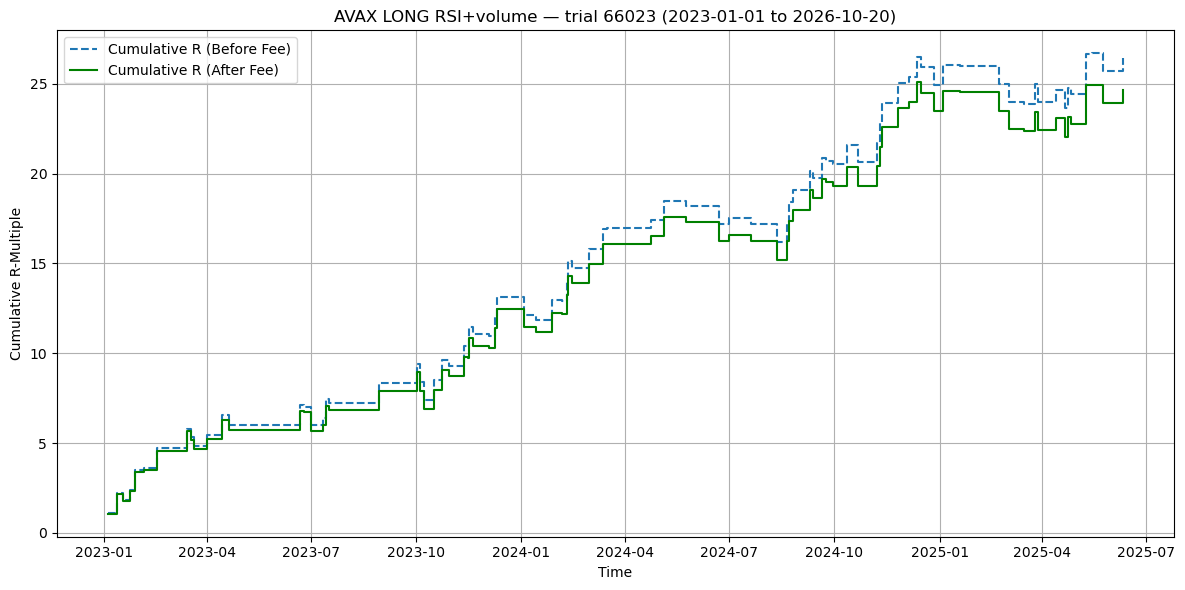

In [36]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này. None = bộ đứng đầu `ranked`.
TRIAL_ID = None
BACKTEST_START_DATE = "2023-01-01"  # Ví dụ "2024-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = "2026-10-20"    # Ví dụ "2025-06-20"; None = ngày kết thúc train

import numpy as np

if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
params = grid.loc[TRIAL_ID].to_dict()
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))

# GPU cho đúng một bộ tham số, và replay float64 liệt kê từng lệnh; hai bên phải khớp.
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, grid.loc[[TRIAL_ID]].reset_index(drop=True), TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS, score_formula=SCORE_FORMULA)
backtest_trial = backtest_result.iloc[0]
trades = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS)
replay = strategy.trade_metrics(backtest_bars, trades)
if replay["number_of_trade"] != int(backtest_trial["number_of_trade"]):
    raise AssertionError(f"Trial {TRIAL_ID}: GPU {int(backtest_trial['number_of_trade'])} lệnh, replay {replay['number_of_trade']}")
if not np.isclose(replay["performance"], float(backtest_trial["performance"]), rtol=1e-4, atol=1e-3):
    raise AssertionError(f"Trial {TRIAL_ID}: tổng R replay khác performance GPU")

print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
display(backtest_trial.to_frame(name="backtest_trial").T)
print(f"Trial {TRIAL_ID}: {replay['number_of_trade']} lệnh; performance replay = {replay['performance']:.6f} R; "
      f"GPU = {backtest_trial['performance']:.6f} R")
display(trades["outcome"].value_counts().to_frame("số lệnh"))
display(trades.head(20))

if trades.empty:
    print("Không có lệnh nào trong khoảng backtest")
else:
    ordered = trades.sort_values("close_timestamp")
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.step(ordered["close_timestamp"], ordered["gross_r"].cumsum(), where="post",
            linestyle="--", label="Cumulative R (Before Fee)")
    ax.step(ordered["close_timestamp"], ordered["net_r"].cumsum(), where="post",
            color="green", label="Cumulative R (After Fee)")
    ax.set(xlabel="Time", ylabel="Cumulative R-Multiple",
           title=f"AVAX LONG RSI+volume — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    plt.show()

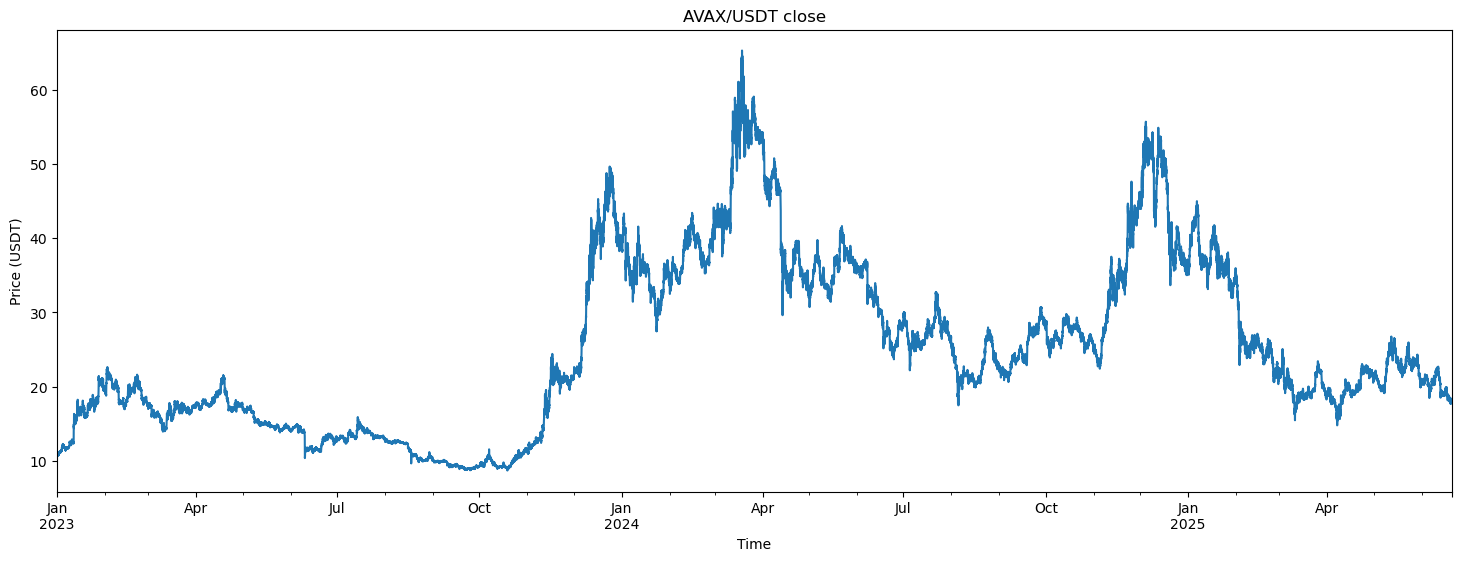

In [37]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()